# c7 · Step 7: Architecture

Input (c5) and optimisation (c6) fixed. Order: cheap local choices on the small model first, then the big
question (depth, BatchNorm, skip connections), then width. 3 seeds per option, same `compare`/`pick` rule.

| # | Question | Options |
|---|---|---|
| 1 | kernel size | **3×3 everywhere**, 5×5 everywhere, 7×7 stem + 3×3 |
| 2 | downsampling | **max-pool**, average-pool, strided convolution |
| 3 | depth × BatchNorm × skip connections | 5 / 9 / 17 / 33 conv layers; plain vs residual; BN on/off |
| 4 | width | base channels 16 / 32 (doubling per stage); 64 is left for the desktop scale-up notebook |

**Why two candidates leave this notebook.** Regularisation (c8) helps models that overfit, which deep models do
more than small ones. Choosing between "small" and "deep" *before* regularisation could reject the deep model for
a problem that c8 fixes. So c7 hands over the best small model **and** the best deep model, and c8 decides.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run, build_model
from lib.models import n_params, n_conv_layers
from lib.report import run_seeds, compare, pick, log_progress
from lib.data import ARTIFACTS
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
INPUT = json.loads((ARTIFACTS / "input.json").read_text())
OPTIM = json.loads((ARTIFACTS / "optim.json").read_text())
CUR = replace(Config(exp="c7", name="x", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]), **INPUT, **OPTIM)
BASE_RUNS = run_seeds(replace(CUR, name="base"))
print(INPUT, OPTIM, proto)

{'mode': 'gray', 'resize': 'crop', 'size': 128, 'normalize': 'per_image'} {'optimizer': 'adam', 'lr': 0.03, 'batch_size': 64, 'schedule': 'none', 'loss': 'label_smoothing', 'sampler': 'none'} {'monitor': 'val_bal_acc', 'patience': 20, 'epochs': 60}


## 1. Kernel size

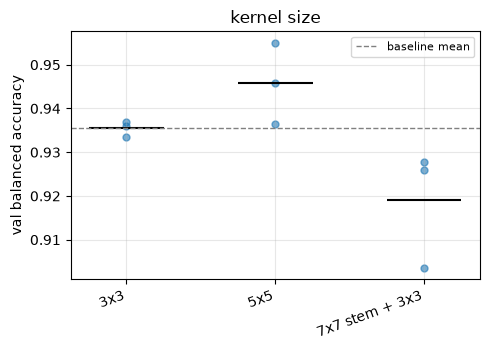

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
3x3,0.9355,0.0019,3.0,0.0000,0.0505,0.9343,0.9944,0.9444,53.6667,100244.0,0.5547
5x5,0.9458,0.0093,3.0,0.0103,0.0505,0.9410,0.9955,0.9583,45.0000,276628.0,0.6684
7x7 stem + 3x3,0.9190,0.0135,3.0,-0.0165,0.0505,0.9136,0.9938,0.9097,41.3333,100884.0,0.5946


chosen: 5x5


In [2]:
ker = {"3x3": BASE_RUNS, "5x5": run_seeds(replace(CUR, name="k5", kernel=5, stem_kernel=5)),
       "7x7 stem + 3x3": run_seeds(replace(CUR, name="stem7", stem_kernel=7))}
t = compare(ker, "3x3", "kernel size"); display(t)
K = pick(t, "3x3"); CUR = replace(CUR, **{"3x3": {}, "5x5": dict(kernel=5, stem_kernel=5), "7x7 stem + 3x3": dict(stem_kernel=7)}[K])
cur_runs = ker[K]; print("chosen:", K)

_TODO kernel_

## 2. Downsampling

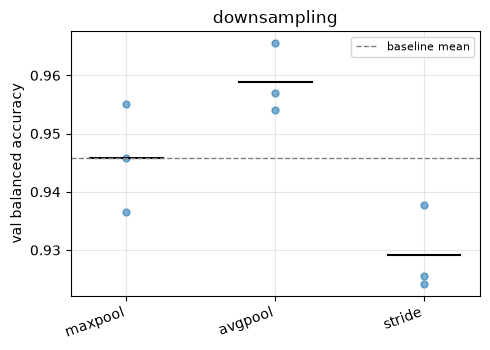

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
maxpool,0.9458,0.0093,3.0,0.0000,0.0505,0.9410,0.9955,0.9583,45.0000,276628.0,0.6684
avgpool,0.9588,0.0060,3.0,0.0130,0.0505,0.9557,0.9958,0.9548,52.6667,276628.0,0.6605
stride,0.9292,0.0074,3.0,-0.0166,0.0505,0.9231,0.9898,0.9236,57.0000,276628.0,0.5475


chosen: avgpool


In [3]:
tagk = f"k{CUR.kernel}s{CUR.stem_kernel}"
down = {"maxpool": cur_runs, "avgpool": run_seeds(replace(CUR, name=f"{tagk}_avg", downsample="avgpool")),
        "stride": run_seeds(replace(CUR, name=f"{tagk}_stride", downsample="stride"))}
t = compare(down, "maxpool", "downsampling"); display(t)
D = pick(t, "maxpool"); CUR = replace(CUR, downsample=D); cur_runs = down[D]; print("chosen:", D)
SMALL = CUR

_TODO down_

## 3. Depth, BatchNorm and skip connections
Depth is counted in 3×3 conv layers (excluding 1×1 shortcut projections), widths fixed at 16-32-64-128.
* **plain**: a stack of conv-BN-ReLU layers, `depths=(n, n, n, n)` single blocks
* **residual**: ResNet basic blocks (two convs + identity shortcut), the same number of conv layers
* **no BN**: the same nets without BatchNorm (conv bias instead)

Besides val score, the **training loss** shows whether a net is hard to *optimise*. If a deeper plain net ends
with a *higher* training loss than a shallower one, that is the degradation problem that skip connections were
invented to fix, not overfitting.

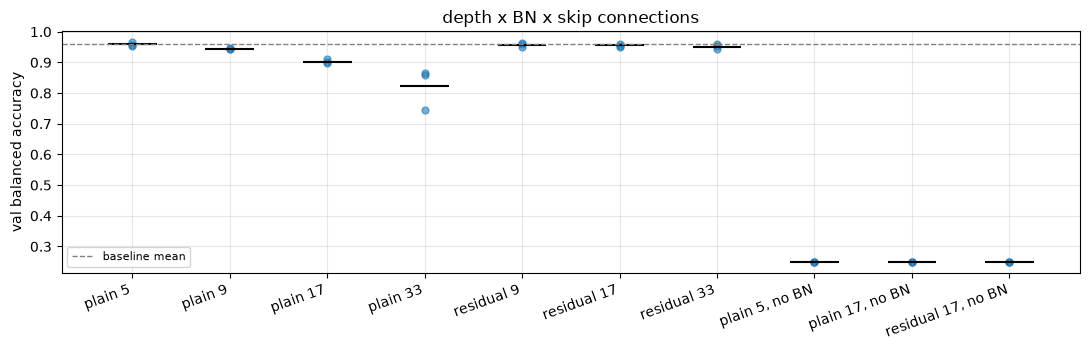

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
plain 5,0.9588,0.0060,3.0,0.0000,0.0505,0.9557,0.9958,0.9548,52.6667,276628.0,0.6605
plain 9,0.9446,0.0020,3.0,-0.0142,0.0505,0.9457,0.9960,0.9236,60.0000,821108.0,1.0384
plain 17,0.9028,0.0064,3.0,-0.0560,0.0505,0.8920,0.9844,0.9097,60.0000,1910068.0,1.8396
plain 33,0.8233,0.0683,3.0,-0.1355,0.0505,0.8034,0.9555,0.8611,55.6667,4087988.0,3.4630
residual 9,0.9583,0.0077,3.0,-0.0005,0.0505,0.9579,0.9961,0.9479,55.6667,832308.0,1.0930
residual 17,0.9555,0.0052,3.0,-0.0033,0.0505,0.9551,0.9902,0.9444,60.0000,1921268.0,1.9412
residual 33,0.9516,0.0076,3.0,-0.0072,0.0505,0.9497,0.9897,0.9410,58.0000,4099188.0,3.5617
"plain 5, no BN",0.2500,0.0000,3.0,-0.7088,0.0505,0.1364,0.5120,0.0000,21.0000,276372.0,0.5361
"plain 17, no BN",0.2500,0.0000,3.0,-0.7088,0.0505,0.1364,0.5000,0.0000,21.0000,1909092.0,1.5449
"residual 17, no BN",0.2500,0.0000,3.0,-0.7088,0.0505,0.1364,0.4855,0.0000,21.0000,1920068.0,1.6044


In [4]:
DEPTHS = {5: dict(block="single", depths=(1, 1, 1, 1)), 9: dict(block="single", depths=(2, 2, 2, 2)),
          17: dict(block="single", depths=(4, 4, 4, 4)), 33: dict(block="single", depths=(8, 8, 8, 8))}
RES = {9: dict(block="basic", residual=True, depths=(1, 1, 1, 1)), 17: dict(block="basic", residual=True, depths=(2, 2, 2, 2)),
       33: dict(block="basic", residual=True, depths=(4, 4, 4, 4))}
tag = f"{tagk}_{D}"
arch = {"plain 5": cur_runs}
for d in [9, 17, 33]:
    arch[f"plain {d}"] = run_seeds(replace(CUR, name=f"{tag}_plain{d}", **DEPTHS[d]))
for d in [9, 17, 33]:
    arch[f"residual {d}"] = run_seeds(replace(CUR, name=f"{tag}_res{d}", **RES[d]))
arch["plain 5, no BN"] = run_seeds(replace(CUR, name=f"{tag}_plain5_nobn", norm=False))
arch["plain 17, no BN"] = run_seeds(replace(CUR, name=f"{tag}_plain17_nobn", norm=False, **DEPTHS[17]))
arch["residual 17, no BN"] = run_seeds(replace(CUR, name=f"{tag}_res17_nobn", norm=False, **RES[17]))
t = compare(arch, "plain 5", "depth x BN x skip connections"); display(t)

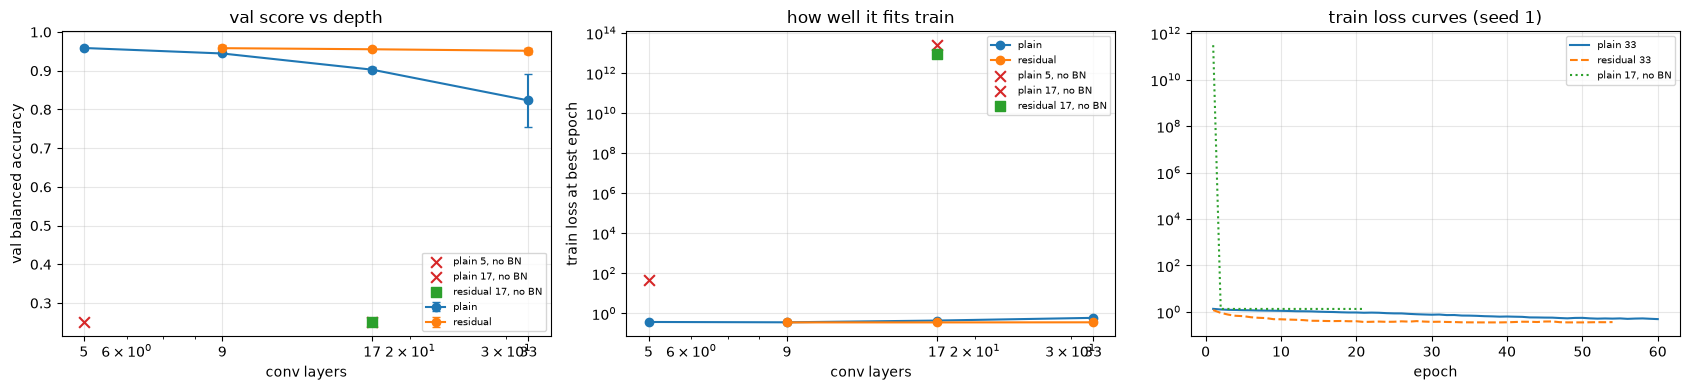

In [5]:
def final_train_loss(rs):  # training loss at the selected (best) epoch, mean over seeds
    return np.mean([r["history"][r["best_epoch"] - 1]["train_loss"] for r in rs])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for fam, keys, c in [("plain", ["plain 5", "plain 9", "plain 17", "plain 33"], "C0"),
                     ("residual", ["residual 9", "residual 17", "residual 33"], "C1")]:
    xs = [int(k.split()[1]) for k in keys]
    ax[0].errorbar(xs, t.loc[keys].bal_acc.astype(float), yerr=t.loc[keys].sd.astype(float), marker="o", capsize=3, color=c, label=fam)
    ax[1].plot(xs, [final_train_loss(arch[k]) for k in keys], marker="o", color=c, label=fam)
for k, mk in [("plain 5, no BN", "x"), ("plain 17, no BN", "x"), ("residual 17, no BN", "s")]:
    x = int(k.split()[1].strip(","))
    ax[0].scatter(x, t.loc[k].bal_acc, marker=mk, color="C3" if "plain" in k else "C2", s=60, label=k, zorder=3)
    ax[1].scatter(x, final_train_loss(arch[k]), marker=mk, color="C3" if "plain" in k else "C2", s=60, label=k, zorder=3)
ax[0].set(xscale="log", xlabel="conv layers", ylabel="val balanced accuracy", title="val score vs depth")
ax[1].set(xscale="log", yscale="log", xlabel="conv layers", ylabel="train loss at best epoch", title="how well it fits train")
for k, ls in [("plain 33", "-"), ("residual 33", "--"), ("plain 17, no BN", ":")]:
    h = pd.DataFrame(arch[k][0]["history"]); ax[2].plot(h.epoch, h.train_loss, ls=ls, label=k)
ax[2].set(yscale="log", xlabel="epoch", title="train loss curves (seed 1)")
for a in ax: a.grid(alpha=0.3); a.legend(fontsize=7)
for a in ax[:2]: a.set_xticks([5, 9, 17, 33], ["5", "9", "17", "33"])
plt.tight_layout(); plt.show()

_TODO depth_

In [6]:
deep_keys = [k for k in arch if k.split()[1].strip(",").isdigit() and int(k.split()[1].strip(",")) >= 17 and "no BN" not in k]
DEEP_KEY = t.loc[deep_keys].bal_acc.astype(float).idxmax()
DEEP = replace(CUR, **(RES if DEEP_KEY.startswith("residual") else DEPTHS)[int(DEEP_KEY.split()[1])])
SMALL_KEY = pick(t.loc[[k for k in arch if "no BN" not in k and int(k.split()[1]) < 17]], "plain 5")
print("best deep candidate:", DEEP_KEY, "| best small candidate:", SMALL_KEY)

best deep candidate: residual 17 | best small candidate: plain 5


## 4. Width (on the deep candidate)

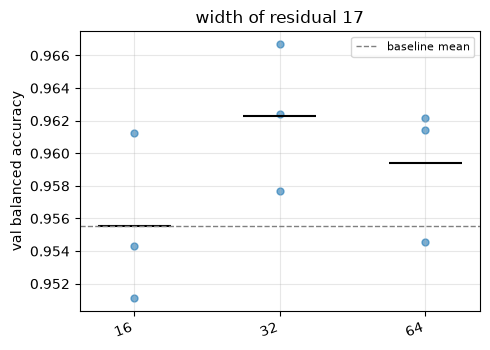

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
16,0.9555,0.0052,3.0,0.0000,0.0505,0.9551,0.9902,0.9444,60.0000,1921268.0,1.9412
32,0.9623,0.0045,3.0,0.0067,0.0505,0.9613,0.9943,0.9444,55.6667,7678436.0,4.0259
64,0.9594,0.0042,3.0,0.0038,0.0505,0.9578,0.9955,0.9514,60.0000,30700484.0,9.0787


chosen width: 32


In [7]:
W = {16: (16, 32, 64, 128), 32: (32, 64, 128, 256), 64: (64, 128, 256, 512)}
wid = {"16": arch[DEEP_KEY]}
for w in [32, 64]:
    wid[str(w)] = run_seeds(replace(DEEP, name=f"{tag}_{DEEP_KEY.replace(' ', '')}_w{w}", widths=W[w]))
t_w = compare(wid, "16", f"width of {DEEP_KEY}"); display(t_w)
WBEST = int(pick(t_w, "16")); DEEP = replace(DEEP, widths=W[WBEST]); print("chosen width:", WBEST)

_TODO width_

## Decisions

_TODO summary_

In [8]:
keys = ["widths", "depths", "kernel", "stem_kernel", "block", "norm", "residual", "downsample"]
SMALL_ARCH = {k: getattr(replace(SMALL, **(DEPTHS.get(int(SMALL_KEY.split()[1]), {}) if SMALL_KEY.startswith("plain")
                                          else RES[int(SMALL_KEY.split()[1])])), k) for k in keys}
DEEP_ARCH = {k: getattr(DEEP, k) for k in keys}
for m, a in [("small", SMALL_ARCH), ("deep", DEEP_ARCH)]:
    net = build_model(replace(CUR, **a), 3 if CUR.mode == "rgb" else 1); print(f"{m}: {n_conv_layers(net)} conv layers, {n_params(net):,} params", a)
_ = (ARTIFACTS / "arch.json").write_text(json.dumps({"small": SMALL_ARCH, "deep": DEEP_ARCH}, default=list))
_ = log_progress("c7 small arch", cur_runs if SMALL_KEY == "plain 5" else arch[SMALL_KEY])
_ = log_progress("c7 deep arch", wid[str(WBEST)])

small: 5 conv layers, 276,628 params {'widths': (16, 32, 64, 128), 'depths': (1, 1, 1, 1), 'kernel': 5, 'stem_kernel': 5, 'block': 'single', 'norm': True, 'residual': False, 'downsample': 'avgpool'}
deep: 17 conv layers, 7,678,436 params {'widths': (32, 64, 128, 256), 'depths': (2, 2, 2, 2), 'kernel': 5, 'stem_kernel': 5, 'block': 'basic', 'norm': True, 'residual': True, 'downsample': 'avgpool'}
